# Session 9: Your first classifier

Data Science track, live session of 2 hours. Code-along notebook.

By the end of this session you will be able to:

1. Explain why a model must beat a simple baseline, and compute that baseline.
2. Split data into training and test sets, and spot overfitting.
3. Read a confusion matrix and explain recall and precision in plain words.
4. Choose a decision threshold to match a business goal.

Data: 1,599 Portuguese red wines with 11 lab measurements and a taster score from 0 to 10 (UCI Machine Learning Repository, Wine Quality dataset by Cortez and colleagues, 2009, licence CC BY 4.0).

Our question: can we flag the wines tasters rate as good (score 7 or higher) from lab measurements alone?

## 0. Setup

On Google Colab, run the next cell once. It downloads the course files. On your own computer, skip it.

In [1]:
import os
if not os.path.exists("data/raw/winequality-red.csv"):
    !git clone -q https://github.com/kardokhk/ds-genai-teaching-samples
    %cd ds-genai-teaching-samples

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score

SEED = 42  # fixed so everyone in the class gets the same numbers
pd.set_option("display.precision", 3)

## 1. Look at the data first

Always look before you model. How many rows? Any missing values? What does one row mean?

In [3]:
wine = pd.read_csv("data/raw/winequality-red.csv", sep=";")
wine.columns = [c.replace(" ", "_") for c in wine.columns]
print(wine.shape)
print("Missing values:", wine.isna().sum().sum())
wine.head()

(1599, 12)
Missing values: 0


,fixed_acidity,volatile_acidity,citric_acid,residual_sugar,chlorides,free_sulfur_dioxide,total_sulfur_dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.997,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.997,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.998,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.998,3.51,0.56,9.4,5


**Checkpoint 1.** Post the two numbers printed by `wine.shape` in the chat.

In [4]:
wine["good"] = (wine["quality"] >= 7).astype(int)
print(wine["good"].value_counts())
print(f"Share of good wines: {wine['good'].mean():.1%}")

good
0    1382
1     217
Name: count, dtype: int64
Share of good wines: 13.6%


**Poll.** A colleague says: "My model is 87% accurate at spotting good wines." Is that impressive? Vote: yes, no, or it depends.

Keep your answer in mind. The next cell settles it.

## 2. The baseline: a model that does nothing

The simplest possible "model" says *not good* for every wine. How accurate is it?

In [5]:
features = [c for c in wine.columns if c not in ("quality", "good")]
X, y = wine[features], wine["good"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Training wines:", len(y_train), " Test wines:", len(y_test), " Good wines in test:", y_test.sum())

baseline = np.zeros_like(y_test)
print(f"Baseline accuracy: {accuracy_score(y_test, baseline):.1%}")

Training wines: 1279  Test wines: 320  Good wines in test: 43
Baseline accuracy: 86.6%


The do-nothing model scores about 87% because most wines are not good. Any real model has to beat this, and accuracy alone cannot tell us whether it finds the good wines at all.

Why `stratify=y`? It keeps the same share of good wines in the training and test sets, so the test set is a fair sample.

## 3. A decision tree, and what overfitting looks like

A decision tree asks yes or no questions about the measurements. `max_depth` limits how many questions in a row it may ask. We compare accuracy on the data it learned from with accuracy on data it has not seen (5-fold cross-validation inside the training set; the test set stays locked away).

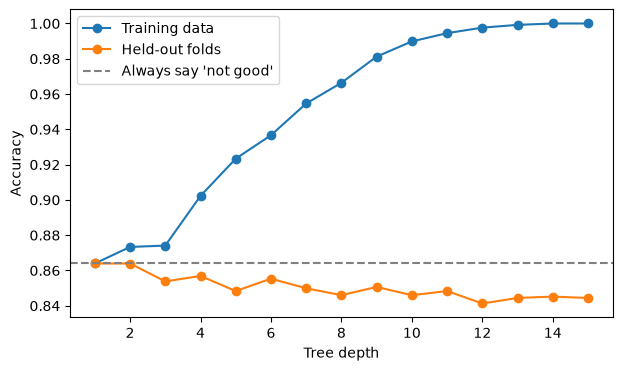

,depth,training,held_out
0,1,0.864,0.864
1,2,0.873,0.864
2,3,0.874,0.854
3,4,0.902,0.857
4,5,0.923,0.848
5,6,0.937,0.855


In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for depth in range(1, 16):
    tree = DecisionTreeClassifier(max_depth=depth, random_state=SEED)
    held_out = cross_val_score(tree, X_train, y_train, cv=cv, scoring="accuracy").mean()
    train_acc = accuracy_score(y_train, tree.fit(X_train, y_train).predict(X_train))
    rows.append({"depth": depth, "training": train_acc, "held_out": held_out})
depth_table = pd.DataFrame(rows)

plt.figure(figsize=(7, 4))
plt.plot(depth_table.depth, depth_table.training, "o-", label="Training data")
plt.plot(depth_table.depth, depth_table.held_out, "o-", label="Held-out folds")
plt.axhline(1 - y.mean(), ls="--", color="grey", label="Always say 'not good'")
plt.xlabel("Tree depth"); plt.ylabel("Accuracy"); plt.legend(); plt.show()
depth_table.round(3).head(6)

Training accuracy climbs towards 100%: the tree memorises the training wines. Held-out accuracy never beats the do-nothing line. That gap is **overfitting**.

**Checkpoint 2.** Which depth has the highest held-out accuracy? Post it in the chat. Then ask yourself: does that tree ever say *good*?

## 4. Better yardsticks: the confusion matrix

Accuracy hides the question we care about. The confusion matrix splits the test wines into four boxes.

- **Recall**: of the truly good wines, what share did we find?
- **Precision**: of the wines we flagged as good, what share really are good?

In [7]:
def report(y_true, y_pred, label):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    print(f"{label}: accuracy {accuracy_score(y_true, y_pred):.1%}, "
          f"recall {recall_score(y_true, y_pred, zero_division=0):.1%} ({tp} of {tp + fn} good wines found), "
          f"precision {precision_score(y_true, y_pred, zero_division=0):.1%} ({tp} of {tp + fp} flags right)")
    return pd.DataFrame([[tn, fp], [fn, tp]],
                        index=["actually not good", "actually good"],
                        columns=["predicted not good", "predicted good"])

report(y_test, baseline, "Baseline")

Baseline: accuracy 86.6%, recall 0.0% (0 of 43 good wines found), precision 0.0% (0 of 0 flags right)


,predicted not good,predicted good
actually not good,277,0
actually good,43,0


## 5. Logistic regression

Logistic regression gives each wine a probability of being good. We scale the measurements first so that each one is on a comparable scale.

In [8]:
logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logreg.fit(X_train, y_train)
proba = logreg.predict_proba(X_test)[:, 1]

report(y_test, (proba >= 0.5).astype(int), "Logistic regression, threshold 0.5")

Logistic regression, threshold 0.5: accuracy 89.4%, recall 37.2% (16 of 43 good wines found), precision 69.6% (16 of 23 flags right)


,predicted not good,predicted good
actually not good,270,7
actually good,27,16


Accuracy is higher than the baseline, but recall shows the model finds only about a third of the good wines.

**Poll.** A wine shop wants to find as many good wines as possible for a tasting panel, and the panel can taste a few extra. Should we raise or lower the threshold?

In [9]:
report(y_test, (proba >= 0.3).astype(int), "Logistic regression, threshold 0.3")

Logistic regression, threshold 0.3: accuracy 87.8%, recall 58.1% (25 of 43 good wines found), precision 54.3% (25 of 46 flags right)


,predicted not good,predicted good
actually not good,256,21
actually good,18,25


Lowering the threshold finds more good wines (recall up) at the cost of more wrong flags (precision down). The right threshold is a business decision, not a statistics one.

A caution on certainty: the test set holds only 43 good wines, so each recall figure carries a wide margin of error. With so few cases, one or two wines more or less changes recall by several points.

## 6. What does the model associate with good wines?

Because we scaled the inputs, the coefficients are comparable: positive means higher values go with higher odds of a good rating.

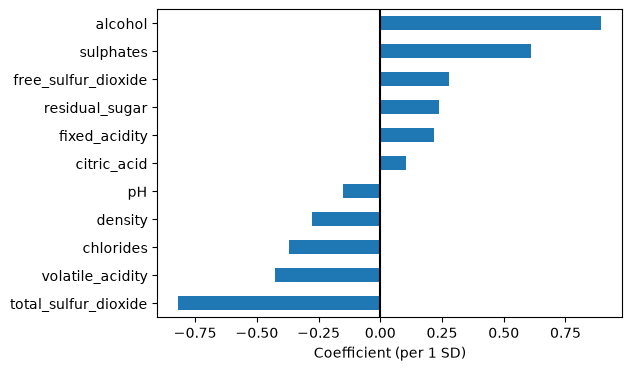

In [10]:
coefs = pd.Series(logreg[-1].coef_[0], index=features).sort_values()
coefs.plot.barh(figsize=(6, 4)); plt.axvline(0, color="black"); plt.xlabel("Coefficient (per 1 SD)"); plt.show()

Alcohol and sulphates go with good ratings; total sulfur dioxide and volatile acidity go against. This is **association**, not cause. These are observational data, so adding alcohol to a wine would not be shown by this model to make it better.

**Checkpoint 3.** Post the measurement with the largest positive coefficient.

## 7. Exercises

1. Retrain logistic regression with `class_weight="balanced"`. What happens to recall and precision at threshold 0.5?
2. Train a decision tree with no depth limit. Compare its training accuracy with its test accuracy. Why should you not choose a model from one test split?
3. Compare logistic regression, balanced logistic regression, the unlimited tree and a random forest (`RandomForestClassifier(n_estimators=300, random_state=SEED)`) using 5-fold cross-validated **balanced accuracy** on the training set. Which would you pick, and why?

In [11]:
# Your work here

## Solutions

In [12]:
# Exercise 1
balanced = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
balanced.fit(X_train, y_train)
report(y_test, balanced.predict(X_test), "Balanced logistic regression")

Balanced logistic regression: accuracy 81.2%, recall 79.1% (34 of 43 good wines found), precision 40.0% (34 of 85 flags right)


,predicted not good,predicted good
actually not good,226,51
actually good,9,34


In [13]:
# Exercise 2
deep = DecisionTreeClassifier(random_state=SEED).fit(X_train, y_train)
print(f"Depth {deep.get_depth()}: training accuracy {accuracy_score(y_train, deep.predict(X_train)):.1%}")
report(y_test, deep.predict(X_test), "Unlimited tree on the test set")

Depth 14: training accuracy 100.0%
Unlimited tree on the test set: accuracy 90.0%, recall 67.4% (29 of 43 good wines found), precision 61.7% (29 of 47 flags right)


,predicted not good,predicted good
actually not good,259,18
actually good,14,29


The tree is perfect on the data it memorised. On this particular test split it does better than cross-validation predicted (about 85% held-out accuracy), which shows how much a single split of 320 wines can move. Choose models with cross-validation on the training data, then check once on the test set.

In [14]:
# Exercise 3
from sklearn.ensemble import RandomForestClassifier
candidates = {
    "logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "balanced logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "unlimited tree": DecisionTreeClassifier(random_state=SEED),
    "random forest": RandomForestClassifier(n_estimators=300, random_state=SEED),
}
for name, model in candidates.items():
    s = cross_val_score(model, X_train, y_train, cv=cv, scoring="balanced_accuracy")
    print(f"{name:30s} balanced accuracy {s.mean():.3f} (SD {s.std(ddof=1):.3f})")

logistic regression            balanced accuracy 0.642 (SD 0.017)
balanced logistic regression   balanced accuracy 0.794 (SD 0.022)
unlimited tree                 balanced accuracy 0.684 (SD 0.040)


random forest                  balanced accuracy 0.664 (SD 0.040)


Balanced logistic regression has the highest cross-validated balanced accuracy, and it is the simplest model to explain. If the wine shop cares most about not wasting panel time, precision matters more, and the random forest (fewer, more accurate flags) becomes attractive. State the goal first, then pick the metric, then the model.